# Plot the steady state spectrum for single configuration

In [12]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

import steady state spectrum properties

In [13]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"


with h5py.File(f"{data_dir}/steady_state_spectrum.h5", "r") as f:
    alpha_inj_grid = f["alpha_inj_grid"][()]
    alpha_inj_e_grid = f["alpha_inj_e_grid"][()]
    log10_B_grid = f["log10_B_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]

    mom_grid = f["electron/mom_grid"][()]
    steady_state_grid_full = f["electron/steady_state_grid"][()]

now evaluate steady state grid for each shock

In [14]:
selected_alphas = [4, 4.2, 4.5]
alpha_inj_colors = ["b", "r", "g"]
alpha_inj_handles = []

for ia, alpha_inj in enumerate(selected_alphas):
    alpha_inj_handles.append(
        mlines.Line2D([0], [0],
            color=alpha_inj_colors[ia],
            lw=2.0,
            alpha=0.8,
            label=rf"$\alpha_\mathrm{{inj, p}} = {alpha_inj}$")
    )

# selected_Bfields = [1e-8, 1e-6, 1e-4]
# Bfield_lss = ["-", "--", ":"]
# bfield_handles = []
# for ib, bfield in enumerate(selected_Bfields):
#     bfield_handles.append(
#         mlines.Line2D([0], [0],
#             color="k",
#             ls=Bfield_lss[ib],
#             lw=2.0,
#             alpha=0.8,
#             label=fr"$\log_{{10}}(B / \mathrm{{G}}) = {np.log10(bfield):.0f}$")
#     )

selected_alpha_es = [4, 4.2, 4.5]
alpha_e_lss = ["-", "--", ":"]
alpha_e_handles = []
for iae, alpha_e in enumerate(selected_alpha_es):
    alpha_e_handles.append(
        mlines.Line2D([0], [0],
            color="k",
            ls=alpha_e_lss[iae],
            lw=2.0,
            alpha=0.8,
            label=rf"$\alpha_\mathrm{{inj, e}} = {alpha_e}$")
    )

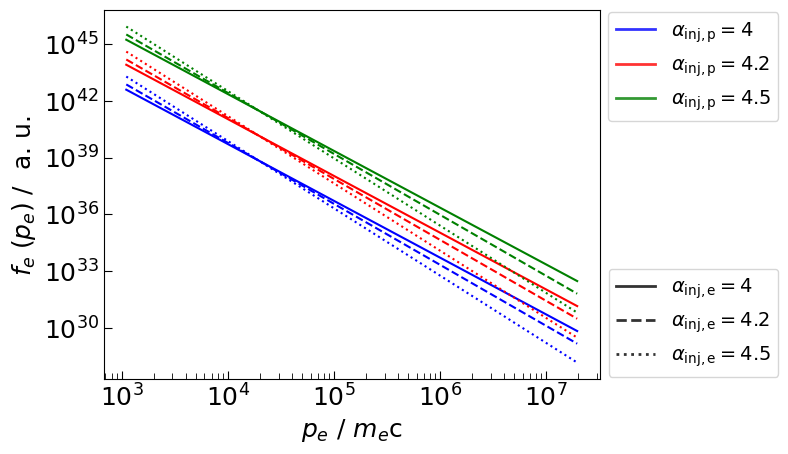

In [16]:
fig, ax = plt.subplots()

bfield_idx = np.digitize(1e-4, 10**log10_B_grid, right=True)
dens_idx = np.digitize(-22, log10_dens_grid, right=True)

for iae, alpha_e in enumerate(selected_alpha_es):
    alpha_inj_e_idx = np.digitize(alpha_e, alpha_inj_e_grid, right=True)

    for ia, alpha_inj in enumerate(selected_alphas):
        alpha_inj_idx = np.digitize(alpha_inj, alpha_inj_grid, right=True)
        steady_state_spect = steady_state_grid_full[ia, dens_idx, alpha_inj_e_idx, bfield_idx, :]
        # steady_state_spect /= np.trapz(4 * np.pi * mom_grid**2 * steady_state_spect, x=mom_grid)

        ax.loglog(mom_grid, steady_state_spect, ls=alpha_e_lss[iae], color=alpha_inj_colors[ia])

ax.set_xlabel(r"$p_e$ / $m_e$c", fontsize=18)
ax.set_ylabel(r"$f_e \; (p_e)$ /  a. u. ", fontsize=18)
# ax.set_ylabel(r"$\hat{f} \; (p)$ / a. u. ", fontsize=18)

# ax.set_xlim(1e2, 1e4)
# ax.set_ylim(1e-14, 1e-7)

ax.tick_params(axis='both', direction="in", which='major', size=6, labelsize=18)
ax.tick_params(axis='both', direction="in", which='minor', size=4, labelsize=16)

leg1 = ax.legend(handles=alpha_inj_handles, loc="upper right", prop={"size":14}, bbox_to_anchor=[1.38, 1.02])
ax.add_artist(leg1)
ax.legend(handles=alpha_e_handles, loc="lower right", prop={"size":14}, bbox_to_anchor=[1.38, -0.02])